In [90]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import pairwise_distances
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.tree import DecisionTreeClassifier

In [91]:
#uploading dataset
dataset = pd.read_csv('academic_success_dataset.csv')

In [92]:
dataset.head(10)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Gender,Scholarship holder,Age at enrollment,International,Unemployment rate,Inflation rate,GDP,Target,Unnamed: 25,Unnamed: 26
0,1.0,17.0,5.0,171.0,1.0,1.0,122.0,1.0,19.0,12.0,...,1.0,0.0,NaN,0.0,10.8,1.4,1.74,Dropout,NaN,NaN
1,1.0,15.0,1.0,9254.0,1.0,1.0,160.0,1.0,1.0,3.0,...,1.0,0.0,19.0,0.0,13.9,-0.3,0.79,Graduate,NaN,NaN
2,1.0,NaN,5.0,9070.0,1.0,1.0,122.0,NaN,37.0,37.0,...,1.0,NaN,19.0,0.0,10.8,1.4,1.74,Dropout,NaN,NaN
3,1.0,17.0,2.0,9773.0,1.0,1.0,122.0,1.0,38.0,37.0,...,NaN,0.0,20.0,0.0,9.4,-0.8,-3.12,Graduate,NaN,NaN
4,2.0,39.0,1.0,8014.0,0.0,1.0,100.0,1.0,37.0,NaN,...,0.0,0.0,NaN,0.0,13.9,-0.3,0.79,Graduate,NaN,NaN
5,2.0,39.0,1.0,9991.0,0.0,19.0,133.1,1.0,37.0,37.0,...,1.0,0.0,50.0,NaN,16.2,0.3,-0.92,Graduate,NaN,NaN
6,1.0,1.0,NaN,9500.0,1.0,1.0,142.0,1.0,19.0,38.0,...,0.0,NaN,18.0,0.0,15.5,2.8,-4.06,Graduate,NaN,NaN
7,1.0,NaN,4.0,9254.0,1.0,1.0,119.0,1.0,37.0,37.0,...,1.0,0.0,22.0,NaN,15.5,2.8,-4.06,Dropout,NaN,NaN
8,NaN,1.0,3.0,9238.0,NaN,1.0,137.0,62.0,1.0,1.0,...,0.0,1.0,21.0,1.0,16.2,0.3,-0.92,NaN,NaN,NaN
9,1.0,1.0,1.0,9238.0,1.0,NaN,138.0,1.0,1.0,19.0,...,0.0,0.0,18.0,0.0,8.9,NaN,3.51,Dropout,NaN,NaN


In [93]:
print(f'shape: {dataset.shape} rows: {dataset.shape[0]} columns: {dataset.shape[1]}')

shape: (4424, 27) rows: 4424 columns: 27


In [94]:
#features:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 27 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Marital status                  4001 non-null   float64
 1   Application mode                3941 non-null   float64
 2   Application order               3998 non-null   float64
 3   Course                          3959 non-null   float64
 4   Daytime/evening attendance	     3984 non-null   float64
 5   Previous qualification          3990 non-null   float64
 6   Previous qualification (grade)  3952 non-null   float64
 7   Nacionality                     3978 non-null   float64
 8   Mother's qualification          4010 non-null   float64
 9   Father's qualification          3974 non-null   float64
 10  Mother's occupation             3988 non-null   float64
 11  Father's occupation             3999 non-null   float64
 12  Admission grade                 39

In [95]:
#select numerical and categorical features
numerical_data = dataset.select_dtypes(include='number')
numerical_features = numerical_data.columns.tolist()
print(f'\nThere are {len(numerical_features)} numerical features:\n', numerical_features)

categorical_data = dataset.select_dtypes(include='object')
categorical_features = categorical_data.columns.tolist()
print(f'\nThere are {len(categorical_features)} categorical features:\n', categorical_features)


There are 26 numerical features:
 ['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance\t', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Unemployment rate', 'Inflation rate', 'GDP', 'Unnamed: 25', 'Unnamed: 26']

There are 1 categorical features:
 ['Target']


In [96]:
#descriptive stats for numerical features
print('\nSummary statistics for numerical features:')
print(numerical_data.describe().T)


Summary statistics for numerical features:
                                 count         mean          std    min  \
Marital status                  4001.0     1.172457     0.584595   1.00   
Application mode                3941.0    18.562040    17.453216   1.00   
Application order               3998.0     1.730865     1.310683   0.00   
Course                          3959.0  8856.628947  2063.151599  33.00   
Daytime/evening attendance\t    3984.0     0.892319     0.310016   0.00   
Previous qualification          3990.0     4.525564    10.132748   1.00   
Previous qualification (grade)  3952.0   132.690056    13.226582  95.00   
Nacionality                     3978.0     1.860985     7.040422   1.00   
Mother's qualification          4010.0    19.482294    15.620541   1.00   
Father's qualification          3974.0    22.203070    15.382146   1.00   
Mother's occupation             3988.0    10.895687    26.304799   0.00   
Father's occupation             3999.0    10.910978    2

In [97]:
#descriptive stats for categorical features
print('\nSummary statistics for categorical features:')
print(categorical_data.describe().T)


Summary statistics for categorical features:
       count unique       top  freq
Target  3971      3  Graduate  1979


In [98]:
#variance of each numerical feature
print('\nVariance of numerical features:')
print(numerical_data.var())


Variance of numerical features:
Marital status                    3.417512e-01
Application mode                  3.046147e+02
Application order                 1.717891e+00
Course                            4.256595e+06
Daytime/evening attendance\t      9.610971e-02
Previous qualification            1.026726e+02
Previous qualification (grade)    1.749425e+02
Nacionality                       4.956754e+01
Mother's qualification            2.440013e+02
Father's qualification            2.366104e+02
Mother's occupation               6.919425e+02
Father's occupation               6.251652e+02
Admission grade                   2.104499e+02
Displaced                         2.475142e-01
Educational special needs         1.143844e-02
Debtor                            1.016493e-01
Tuition fees up to date           1.033817e-01
Gender                            2.283441e-01
Scholarship holder                1.881122e-01
Age at enrollment                 5.788534e+01
International              

In [99]:
#skewness of numerical features
print('\nSkewness of numerical features:')
print(numerical_data.skew())


Skewness of numerical features:
Marital status                     4.429740
Application mode                   0.398201
Application order                  1.872101
Course                            -3.808295
Daytime/evening attendance\t      -2.532235
Previous qualification             2.900447
Previous qualification (grade)     0.307966
Nacionality                       10.924248
Mother's qualification             0.010805
Father's qualification            -0.291581
Mother's occupation                5.383512
Father's occupation                5.488079
Admission grade                    0.515351
Displaced                         -0.203022
Educational special needs          9.138353
Debtor                             2.417568
Tuition fees up to date           -2.383186
Gender                             0.617042
Scholarship holder                 1.148176
Age at enrollment                  2.091374
International                      6.019125
Unemployment rate                  0.207260

C:\Users\Roy\AppData\Local\Temp\ipykernel_20068\1377628989.py:4: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0.03, 1, 0.95])
C:\Users\Roy\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Roy\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


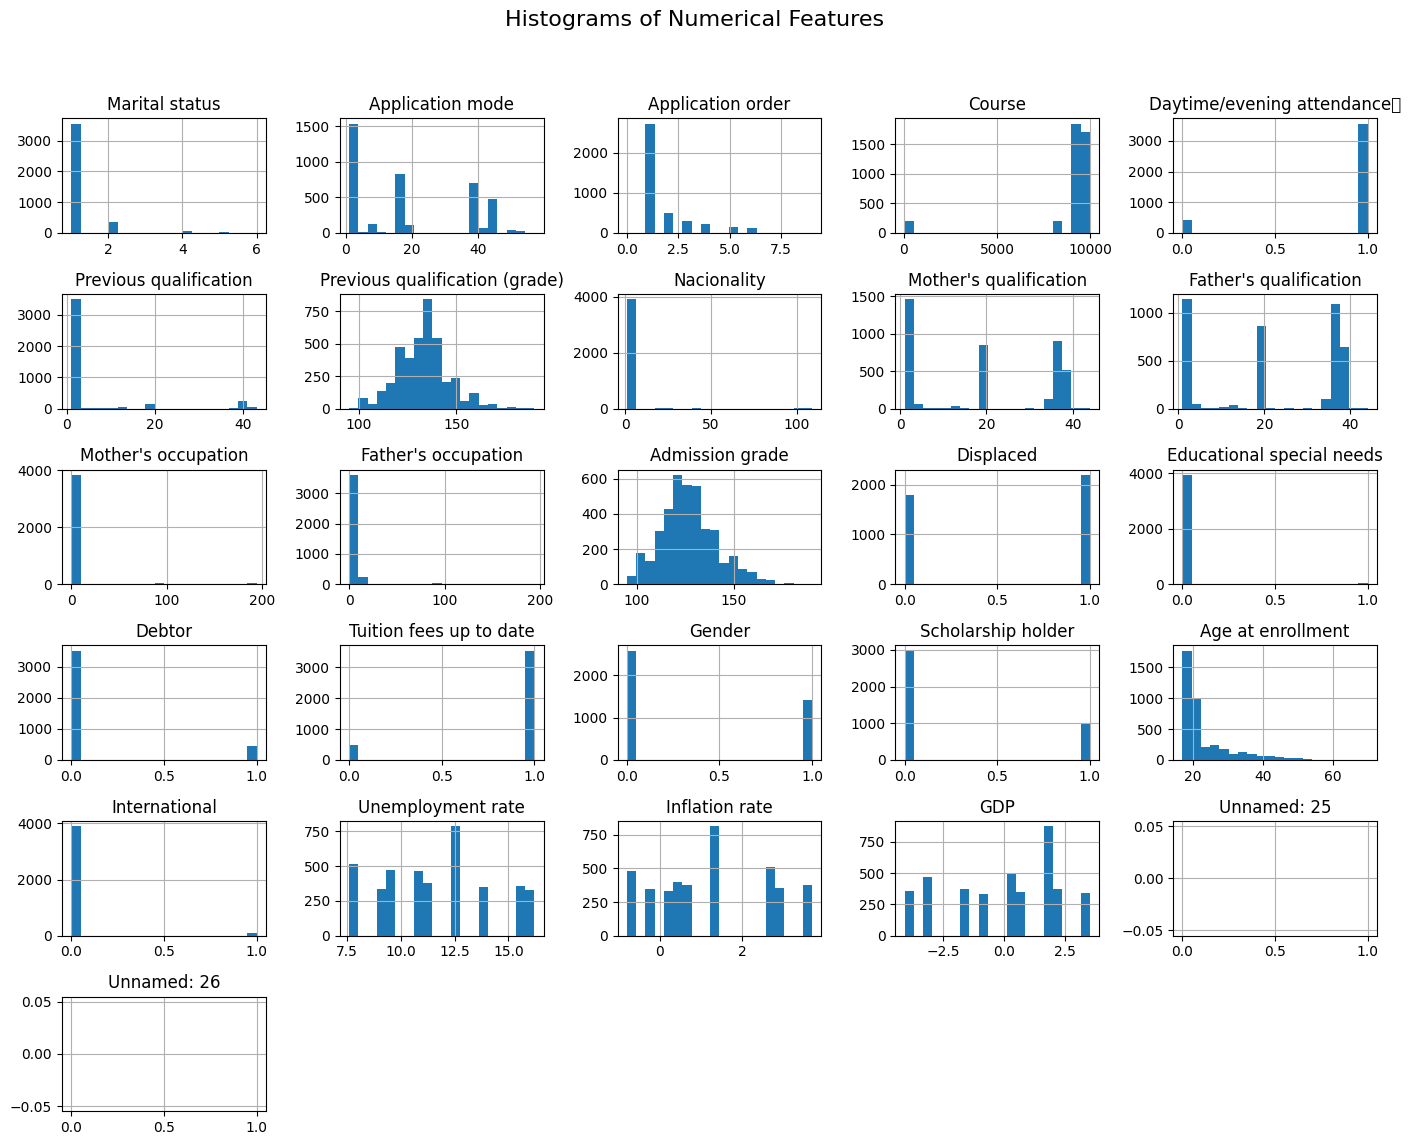

In [100]:
#histograms for numerical features
numerical_data.hist(figsize=(14, 12), bins=20)
plt.suptitle('Histograms of Numerical Features', fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

C:\Users\Roy\AppData\Local\Temp\ipykernel_20068\2909318797.py:10: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Roy\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Roy\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


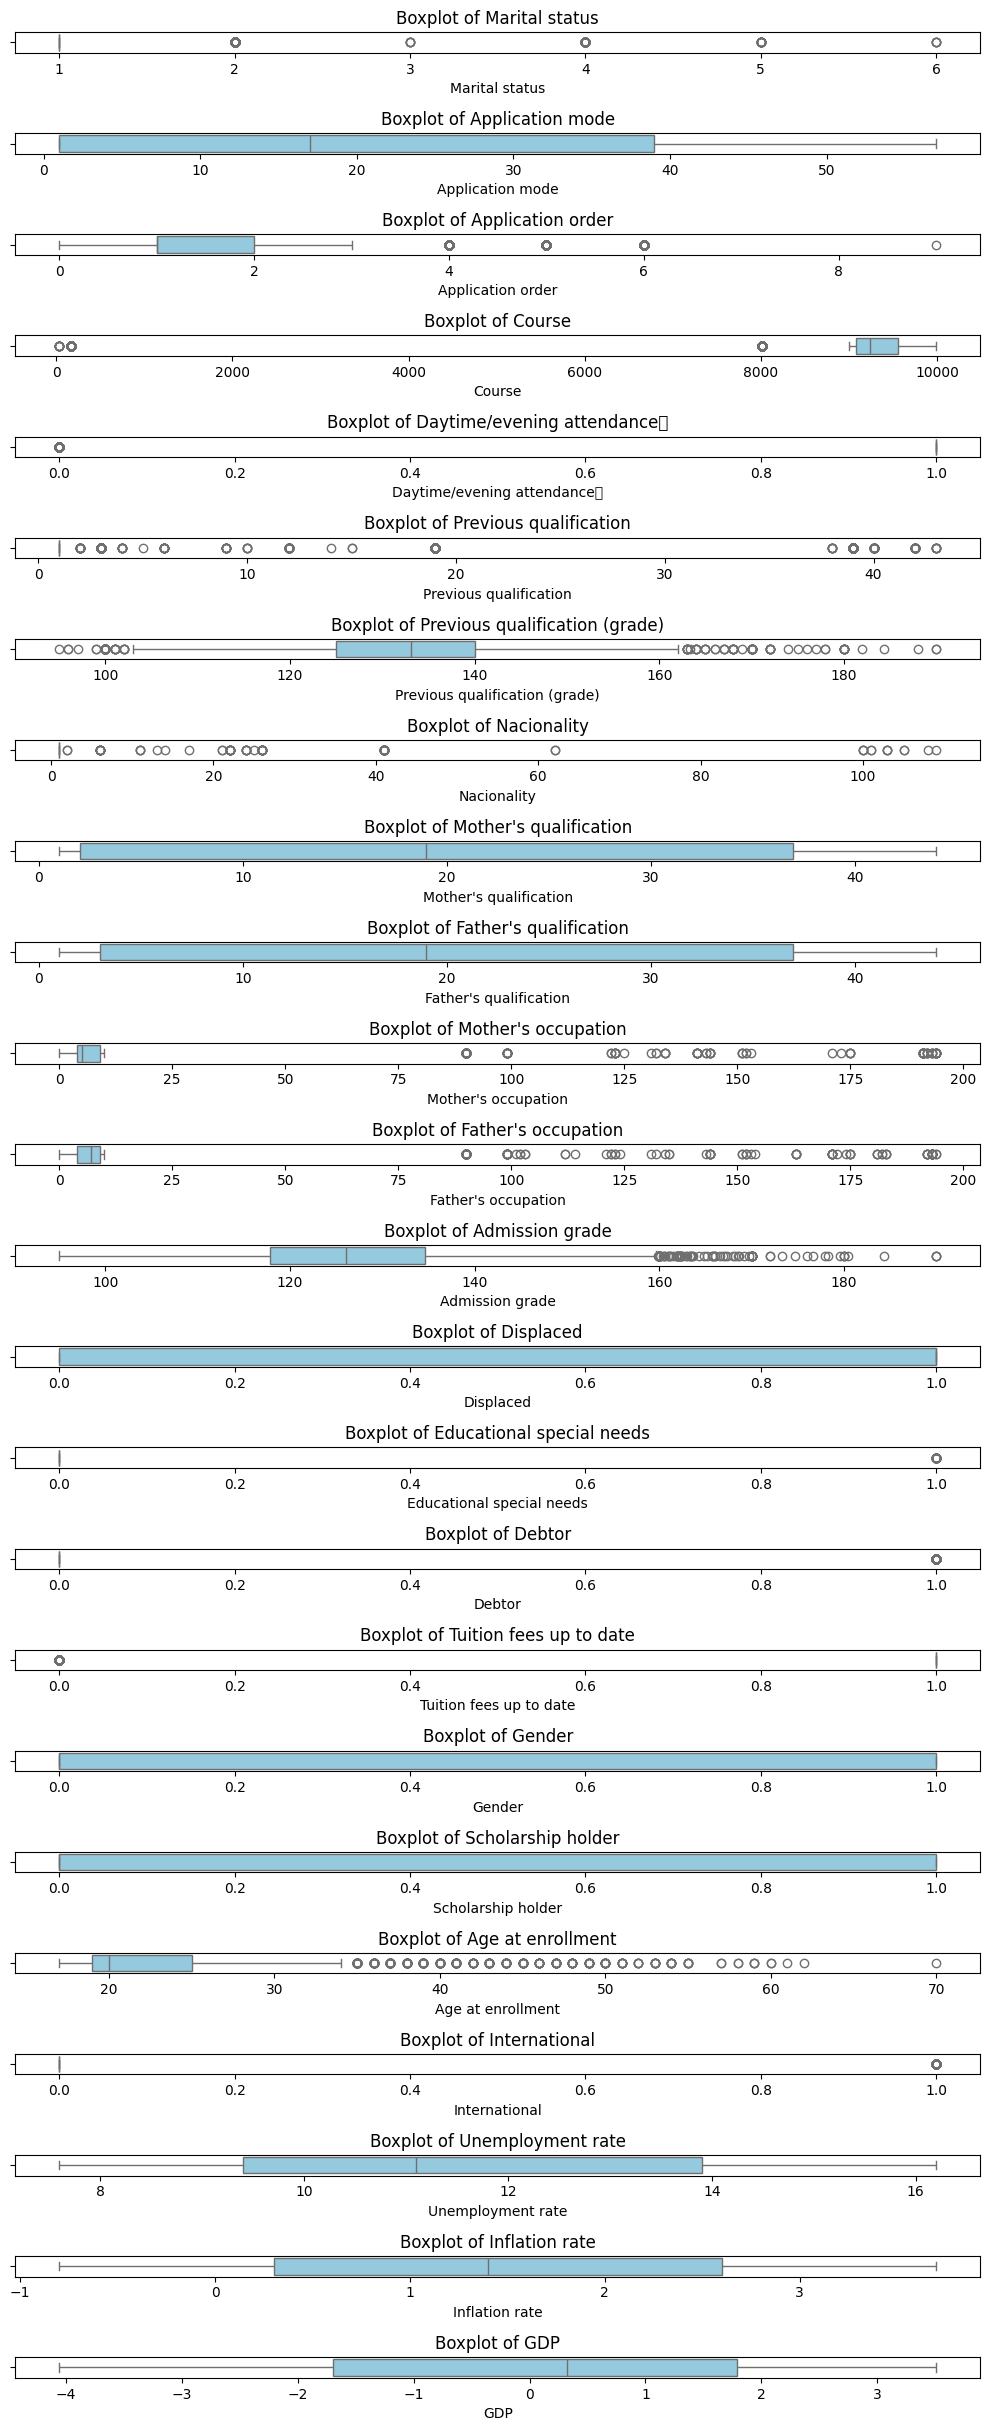

In [101]:
#boxplots for numerical features
plt.figure(figsize=(10,  len(numerical_features)))
plot_idx = 1
for col in numerical_features:
    #plot if there are at least 2 unique values
    if dataset[col].nunique() > 1 and not dataset[col].isnull().all():
        plt.subplot(len(numerical_features), 1, plot_idx)
        sns.boxplot(x=dataset[col], color='skyblue')
        plt.title(f'Boxplot of {col}', fontsize=12)
        plt.tight_layout()
        plot_idx += 1
plt.show()

In [102]:
#number of unique values in each numerical feature
print('\nNumber of unique values in each numerical feature:')
print(numerical_data.nunique())


Number of unique values in each numerical feature:
Marital status                      6
Application mode                   18
Application order                   8
Course                             17
Daytime/evening attendance\t        2
Previous qualification             17
Previous qualification (grade)     98
Nacionality                        20
Mother's qualification             28
Father's qualification             34
Mother's occupation                32
Father's occupation                43
Admission grade                   606
Displaced                           2
Educational special needs           2
Debtor                              2
Tuition fees up to date             2
Gender                              2
Scholarship holder                  2
Age at enrollment                  46
International                       2
Unemployment rate                  10
Inflation rate                      9
GDP                                10
Unnamed: 25                         

In [103]:
#missing values in numerical features
print('\nMissing values in numerical features:')
print(numerical_data.isnull().sum())


Missing values in numerical features:
Marital status                     423
Application mode                   483
Application order                  426
Course                             465
Daytime/evening attendance\t       440
Previous qualification             434
Previous qualification (grade)     472
Nacionality                        446
Mother's qualification             414
Father's qualification             450
Mother's occupation                436
Father's occupation                425
Admission grade                    462
Displaced                          442
Educational special needs          448
Debtor                             452
Tuition fees up to date            426
Gender                             437
Scholarship holder                 450
Age at enrollment                  444
International                      428
Unemployment rate                  429
Inflation rate                     422
GDP                                456
Unnamed: 25              

In [104]:
#unique value counts in categorical features
print('\nUnique value counts in categorical features:')
print(categorical_data.nunique())


Unique value counts in categorical features:
Target    3
dtype: int64


C:\Users\Roy\AppData\Local\Temp\ipykernel_20068\479763679.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, palette="viridis")


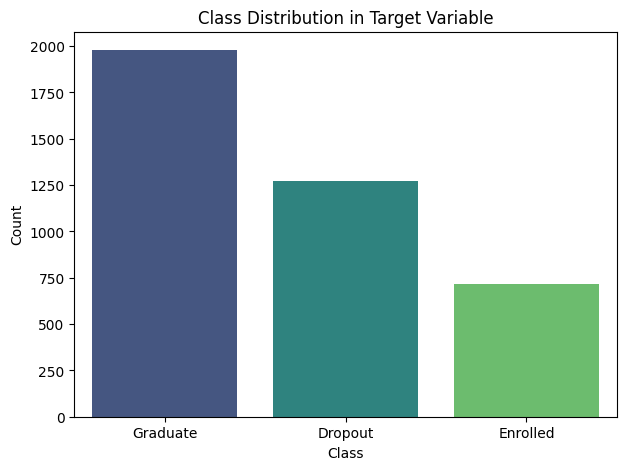

In [105]:
#barplot of unique value counts in each categorical feature
plt.figure(figsize=(7,5))
class_counts = dataset["Target"].value_counts()
sns.barplot(x=class_counts.index, y=class_counts.values, palette="viridis")
plt.title("Class Distribution in Target Variable")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

In [106]:
#correlation analysis
correlation_matrix = numerical_data.corr()
print('\nCorrelation matrix:')
print(correlation_matrix)


Correlation matrix:
                                Marital status  Application mode  \
Marital status                        1.000000          0.272283   
Application mode                      0.272283          1.000000   
Application order                    -0.133386         -0.279194   
Course                                0.049238          0.091408   
Daytime/evening attendance\t         -0.249639         -0.309777   
Previous qualification                0.064128          0.423982   
Previous qualification (grade)       -0.012464         -0.035747   
Nacionality                          -0.000230          0.004130   
Mother's qualification                0.193717          0.114221   
Father's qualification                0.128422          0.090591   
Mother's occupation                   0.042128          0.037101   
Father's occupation                   0.030536          0.017609   
Admission grade                      -0.001851         -0.006797   
Displaced                  

C:\Users\Roy\AppData\Roaming\Python\Python313\site-packages\seaborn\utils.py:61: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
C:\Users\Roy\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Roy\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


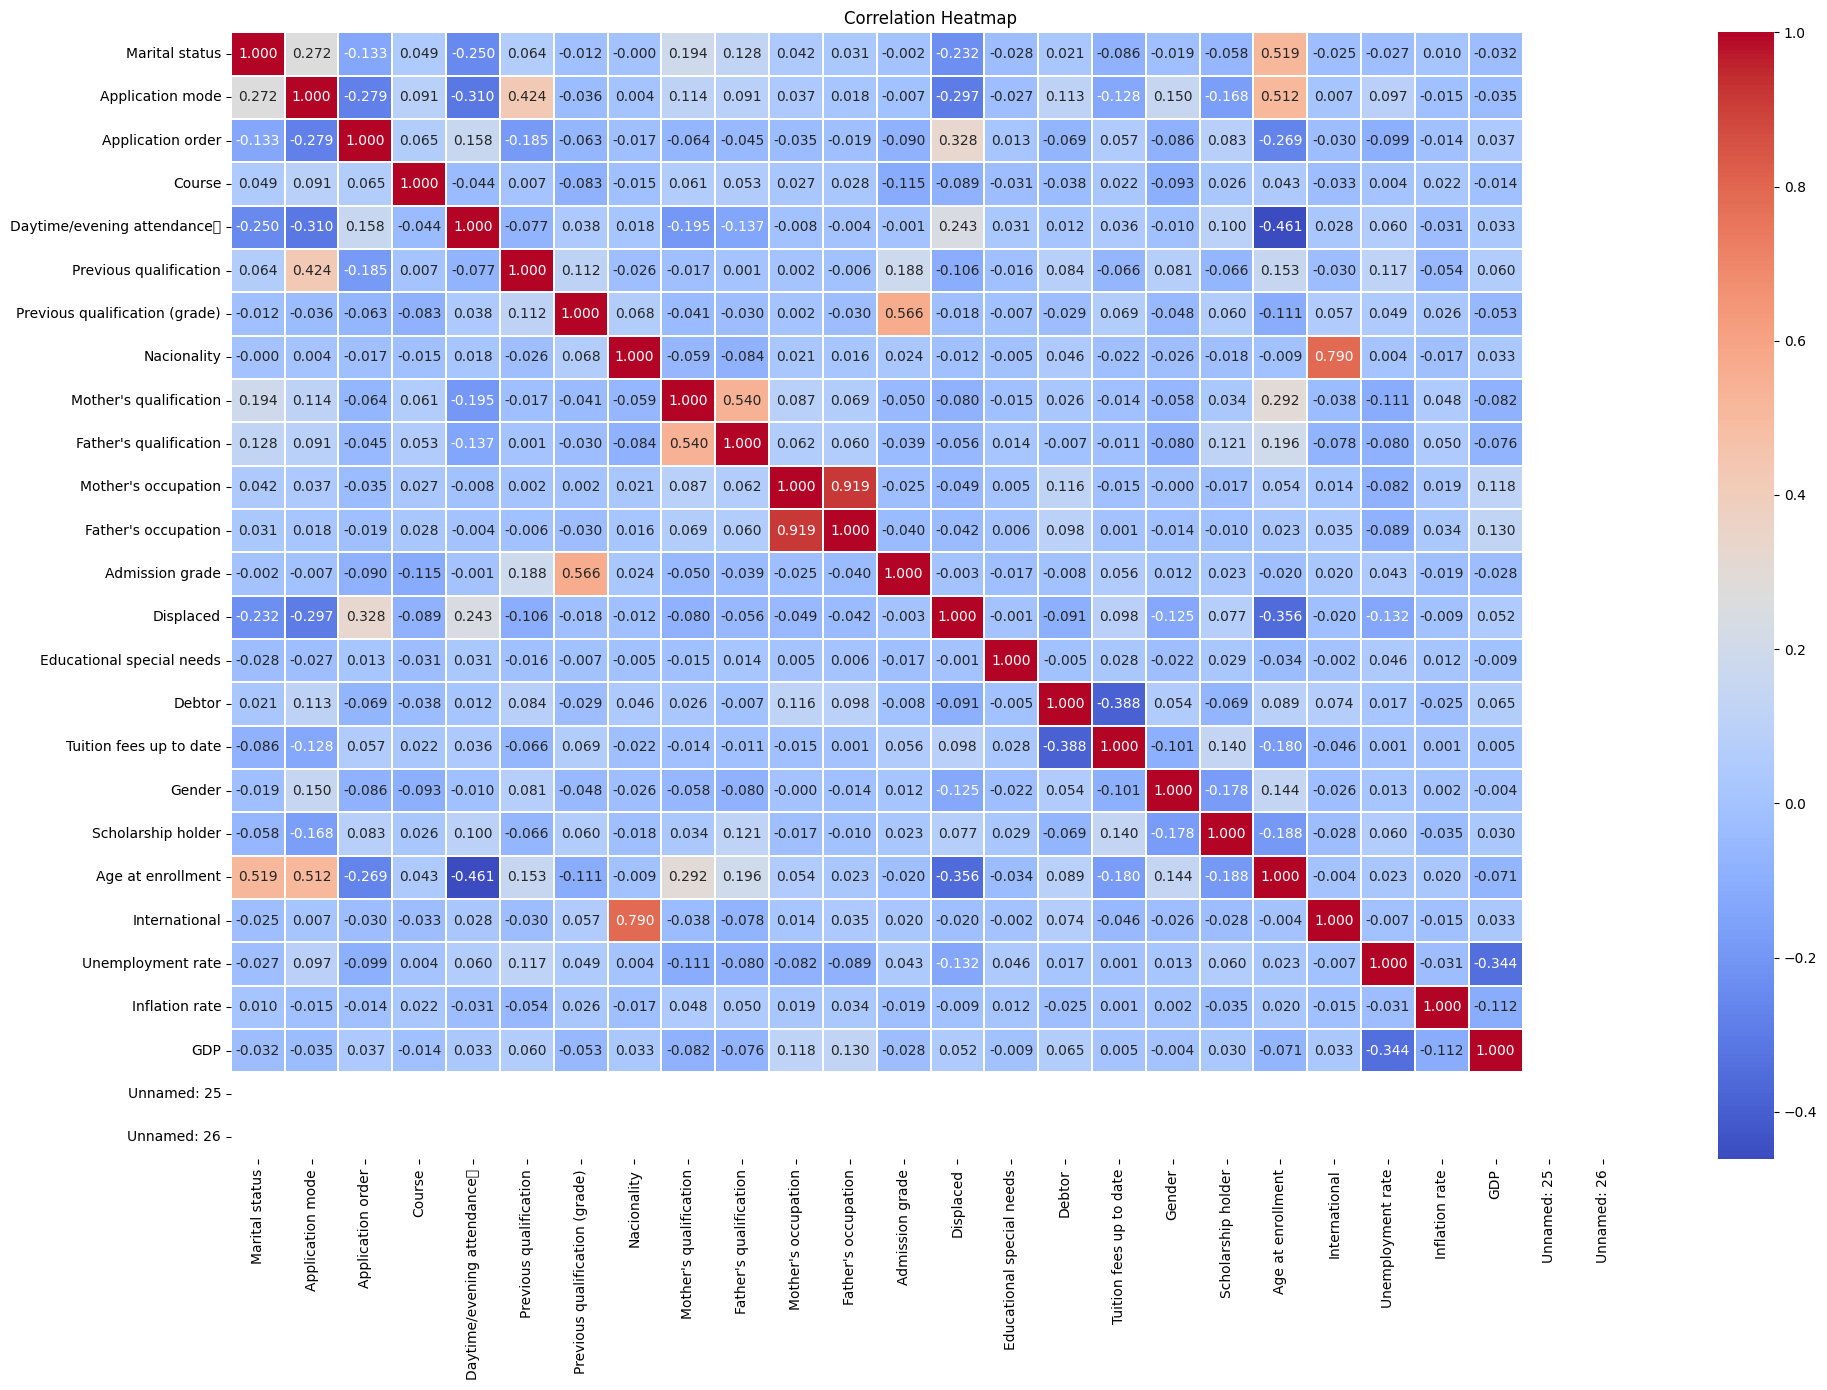

In [107]:
#correlation heatmap
plt.figure(figsize=(20, 14))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.3)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

C:\Users\Roy\AppData\Local\Temp\ipykernel_20068\3673632843.py:5: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Roy\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Roy\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


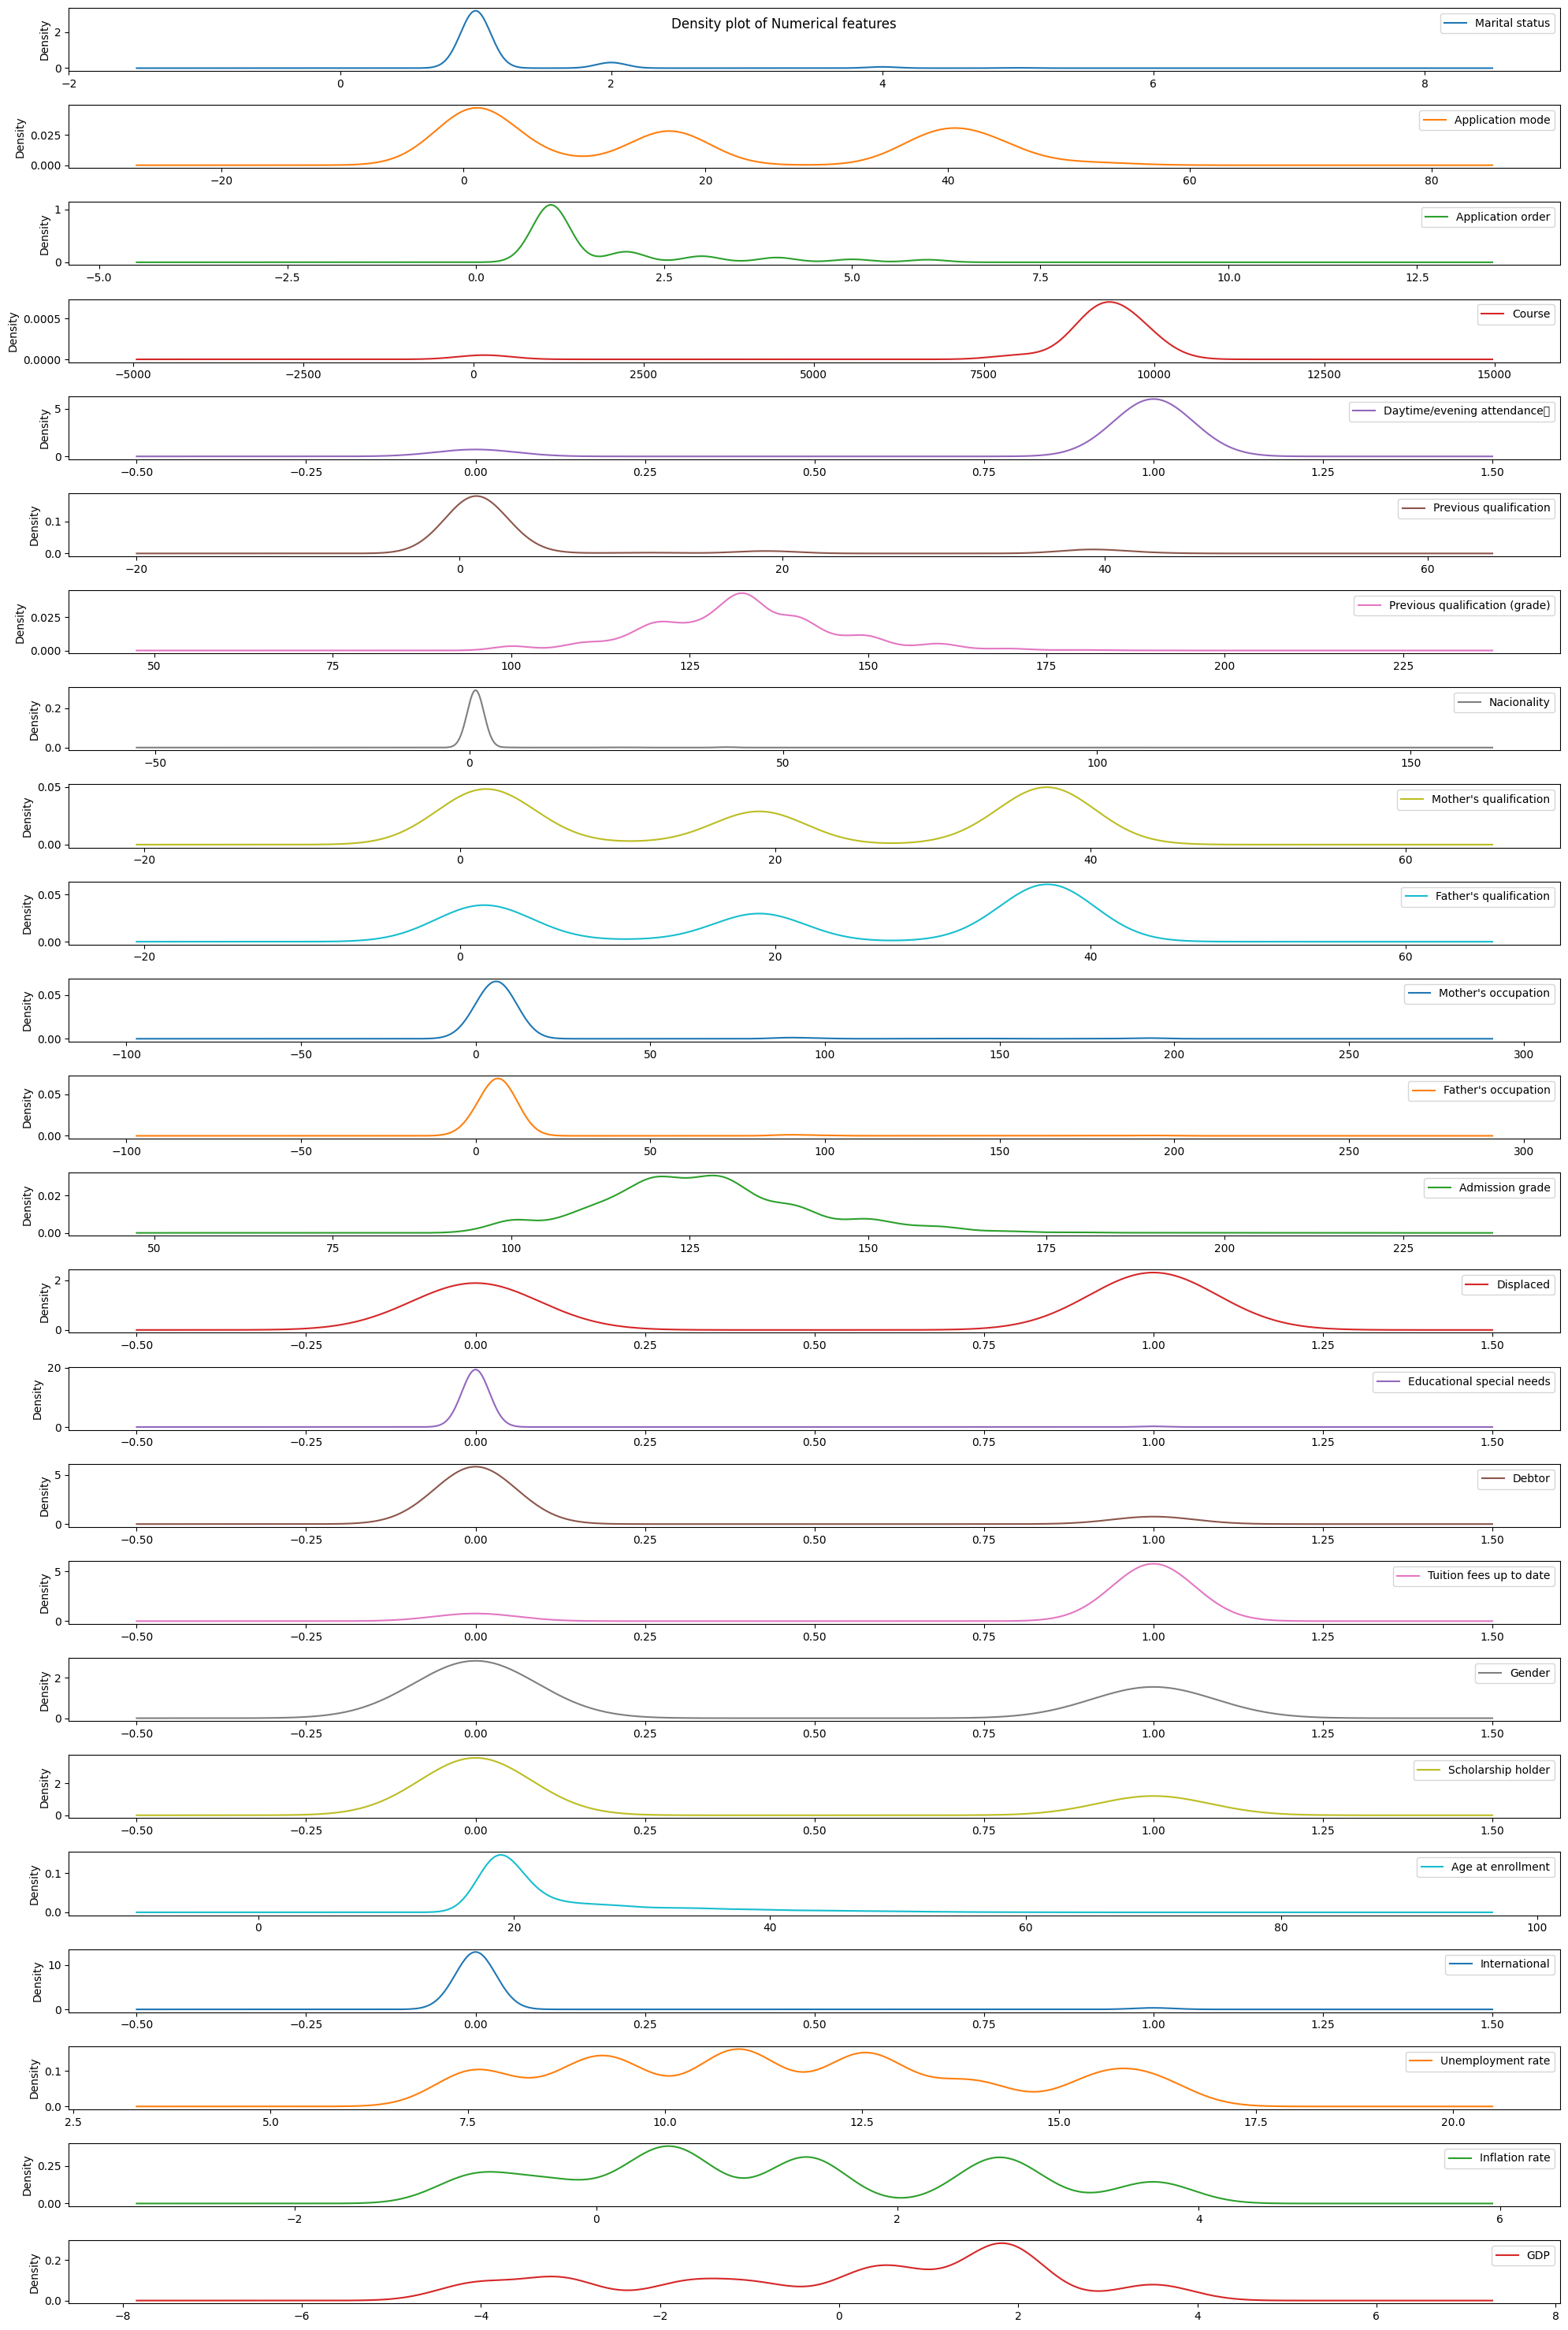


EDA complete.


In [108]:
# Density plots for numerical features (skip columns with only one unique value or all NaNs)
valid_density_cols = [col for col in numerical_features if dataset[col].nunique() > 1 and not dataset[col].isnull().all()]
if valid_density_cols:
    dataset[valid_density_cols].plot(kind='density', figsize=(20, 30), subplots=True, layout=(len(valid_density_cols), 1), title="Density plot of Numerical features", sharex=False)
    plt.tight_layout()
    plt.show()

print('\nEDA complete.')


**DATA Preprocessing**

In [109]:
df = dataset

In [110]:
#drop columns whose names start with 'Unnamed'
unnamed_cols = []
for col in df.columns:
    if col.startswith('Unnamed'):
        unnamed_cols.append(col)
if unnamed_cols:
    df = df.drop(columns=unnamed_cols)

In [111]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Marital status                  4001 non-null   float64
 1   Application mode                3941 non-null   float64
 2   Application order               3998 non-null   float64
 3   Course                          3959 non-null   float64
 4   Daytime/evening attendance	     3984 non-null   float64
 5   Previous qualification          3990 non-null   float64
 6   Previous qualification (grade)  3952 non-null   float64
 7   Nacionality                     3978 non-null   float64
 8   Mother's qualification          4010 non-null   float64
 9   Father's qualification          3974 non-null   float64
 10  Mother's occupation             3988 non-null   float64
 11  Father's occupation             3999 non-null   float64
 12  Admission grade                 39

In [112]:
df.shape

(4424, 25)

In [113]:
#For numerical columns, compare imputation strategies: mean, median, most_frequent
num_cols = df.select_dtypes(include=['number']).columns
if df[num_cols].isnull().sum().sum() > 0:
    print("\nComparing imputation strategies for numerical columns...")
    imputers = {
        'mean': SimpleImputer(strategy='mean'),
        'median': SimpleImputer(strategy='median'),
        'most_frequent': SimpleImputer(strategy='most_frequent')
    }
    scores = {}
    for name, imp in imputers.items():
        temp = df[num_cols].copy()
        temp = pd.DataFrame(imp.fit_transform(temp), columns=num_cols)
        # Use variance preservation as a simple metric
        scores[name] = temp.var().mean()
        print(f"{name} imputation: mean variance = {scores[name]:.4f}")
    best_strategy = max(scores, key=scores.get)
    print(f"Selected '{best_strategy}' imputation for numerical columns (preserves most variance).")
    imputer = imputers[best_strategy]
    df[num_cols] = imputer.fit_transform(df[num_cols])


Comparing imputation strategies for numerical columns...
mean imputation: mean variance = 158813.8545
median imputation: mean variance = 159384.3363
most_frequent imputation: mean variance = 160440.0489
Selected 'most_frequent' imputation for numerical columns (preserves most variance).


In [114]:
#imputing missing values with mode for categorical columns
cat_cols = df.select_dtypes(include=['object', 'category']).columns
for col in cat_cols:
    if df[col].isnull().sum() > 0:
        mode = df[col].mode()[0]
        df[col] = df[col].fillna(mode)
        print(f"Imputed missing values in {col} with mode: {mode}")

Imputed missing values in Target with mode: Graduate


In [115]:
#for target column, compare imputation with mode, most_frequent, and drop
if 'Target' in df.columns and df['Target'].isnull().sum() > 0:
    print("\nComparing imputation strategies for target column...")
    mode = df['Target'].mode()[0]
    most_freq = df['Target'].value_counts().idxmax()
    n_missing = df['Target'].isnull().sum()
    print(f"Target missing: {n_missing}, mode: {mode}, most_frequent: {most_freq}")
    # Option 1: Impute with mode
    impute_mode = df['Target'].fillna(mode)
    # Option 2: Impute with most_frequent
    impute_mf = df['Target'].fillna(most_freq)
    # Option 3: Drop missing
    dropna = df['Target'].dropna()
    # Compare class balance after each
    print("Class distribution after mode imputation:")
    print(impute_mode.value_counts(normalize=True))
    print("Class distribution after most_frequent imputation:")
    print(impute_mf.value_counts(normalize=True))
    print("Class distribution after dropping missing:")
    print(dropna.value_counts(normalize=True))
    # Choose the option that keeps class balance closest to original
    orig_dist = df['Target'].value_counts(normalize=True)
    mode_dist = impute_mode.value_counts(normalize=True)
    mf_dist = impute_mf.value_counts(normalize=True)
    drop_dist = dropna.value_counts(normalize=True)
    def dist_diff(a, b):
        return ((a - b).abs().sum())
    diffs = {
        'mode': dist_diff(orig_dist, mode_dist),
        'most_frequent': dist_diff(orig_dist, mf_dist),
        'drop': dist_diff(orig_dist, drop_dist)
    }
    best = min(diffs, key=diffs.get)
    print(f"Selected '{best}' strategy for target imputation (min class distribution change).")
    if best == 'mode':
        df['Target'] = impute_mode
    elif best == 'most_frequent':
        df['Target'] = impute_mf
    else:
        df = df.dropna(subset=['Target'])


In [116]:
df.head(20)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Unemployment rate,Inflation rate,GDP,Target
0,1.0,17.0,5.0,171.0,1.0,1.0,122.0,1.0,19.0,12.0,...,0.0,1.0,1.0,0.0,18.0,0.0,10.8,1.4,1.74,Dropout
1,1.0,15.0,1.0,9254.0,1.0,1.0,160.0,1.0,1.0,3.0,...,0.0,0.0,1.0,0.0,19.0,0.0,13.9,-0.3,0.79,Graduate
2,1.0,1.0,5.0,9070.0,1.0,1.0,122.0,1.0,37.0,37.0,...,0.0,0.0,1.0,0.0,19.0,0.0,10.8,1.4,1.74,Dropout
3,1.0,17.0,2.0,9773.0,1.0,1.0,122.0,1.0,38.0,37.0,...,0.0,1.0,0.0,0.0,20.0,0.0,9.4,-0.8,-3.12,Graduate
4,2.0,39.0,1.0,8014.0,0.0,1.0,100.0,1.0,37.0,37.0,...,0.0,1.0,0.0,0.0,18.0,0.0,13.9,-0.3,0.79,Graduate
5,2.0,39.0,1.0,9991.0,0.0,19.0,133.1,1.0,37.0,37.0,...,1.0,1.0,1.0,0.0,50.0,0.0,16.2,0.3,-0.92,Graduate
6,1.0,1.0,1.0,9500.0,1.0,1.0,142.0,1.0,19.0,38.0,...,0.0,1.0,0.0,0.0,18.0,0.0,15.5,2.8,-4.06,Graduate
7,1.0,1.0,4.0,9254.0,1.0,1.0,119.0,1.0,37.0,37.0,...,0.0,0.0,1.0,0.0,22.0,0.0,15.5,2.8,-4.06,Dropout
8,1.0,1.0,3.0,9238.0,1.0,1.0,137.0,62.0,1.0,1.0,...,0.0,1.0,0.0,1.0,21.0,1.0,16.2,0.3,-0.92,Graduate
9,1.0,1.0,1.0,9238.0,1.0,1.0,138.0,1.0,1.0,19.0,...,1.0,0.0,0.0,0.0,18.0,0.0,8.9,1.4,3.51,Dropout


In [117]:
#encoding target column
if 'Target' in df.columns:
    print("Encoding 'Target' column: Dropout=0, Enrolled=1, Graduate=2")
    target_map = {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
    df = df.dropna(subset=['Target'])
    df['Target'] = df['Target'].map(target_map)


Encoding 'Target' column: Dropout=0, Enrolled=1, Graduate=2


In [118]:
df.head(20)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Unemployment rate,Inflation rate,GDP,Target
0,1.0,17.0,5.0,171.0,1.0,1.0,122.0,1.0,19.0,12.0,...,0.0,1.0,1.0,0.0,18.0,0.0,10.8,1.4,1.74,0
1,1.0,15.0,1.0,9254.0,1.0,1.0,160.0,1.0,1.0,3.0,...,0.0,0.0,1.0,0.0,19.0,0.0,13.9,-0.3,0.79,2
2,1.0,1.0,5.0,9070.0,1.0,1.0,122.0,1.0,37.0,37.0,...,0.0,0.0,1.0,0.0,19.0,0.0,10.8,1.4,1.74,0
3,1.0,17.0,2.0,9773.0,1.0,1.0,122.0,1.0,38.0,37.0,...,0.0,1.0,0.0,0.0,20.0,0.0,9.4,-0.8,-3.12,2
4,2.0,39.0,1.0,8014.0,0.0,1.0,100.0,1.0,37.0,37.0,...,0.0,1.0,0.0,0.0,18.0,0.0,13.9,-0.3,0.79,2
5,2.0,39.0,1.0,9991.0,0.0,19.0,133.1,1.0,37.0,37.0,...,1.0,1.0,1.0,0.0,50.0,0.0,16.2,0.3,-0.92,2
6,1.0,1.0,1.0,9500.0,1.0,1.0,142.0,1.0,19.0,38.0,...,0.0,1.0,0.0,0.0,18.0,0.0,15.5,2.8,-4.06,2
7,1.0,1.0,4.0,9254.0,1.0,1.0,119.0,1.0,37.0,37.0,...,0.0,0.0,1.0,0.0,22.0,0.0,15.5,2.8,-4.06,0
8,1.0,1.0,3.0,9238.0,1.0,1.0,137.0,62.0,1.0,1.0,...,0.0,1.0,0.0,1.0,21.0,1.0,16.2,0.3,-0.92,2
9,1.0,1.0,1.0,9238.0,1.0,1.0,138.0,1.0,1.0,19.0,...,1.0,0.0,0.0,0.0,18.0,0.0,8.9,1.4,3.51,0


In [119]:
#encoding
cat_cols = []
for col in df.select_dtypes(include=['object', 'category']).columns:
    if col != 'Target':
        cat_cols.append(col)
for col in cat_cols:
    n_unique = df[col].nunique()
    if n_unique == 2:
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col])
        print(f"Label encoded binary column: {col}")
    elif n_unique > 2:
        dummies = pd.get_dummies(df[col], prefix=col)
        df = pd.concat([df.drop(columns=[col]), dummies], axis=1)
        print(f"One-hot encoded column: {col}")

In [120]:
df.head(20)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Unemployment rate,Inflation rate,GDP,Target
0,1.0,17.0,5.0,171.0,1.0,1.0,122.0,1.0,19.0,12.0,...,0.0,1.0,1.0,0.0,18.0,0.0,10.8,1.4,1.74,0
1,1.0,15.0,1.0,9254.0,1.0,1.0,160.0,1.0,1.0,3.0,...,0.0,0.0,1.0,0.0,19.0,0.0,13.9,-0.3,0.79,2
2,1.0,1.0,5.0,9070.0,1.0,1.0,122.0,1.0,37.0,37.0,...,0.0,0.0,1.0,0.0,19.0,0.0,10.8,1.4,1.74,0
3,1.0,17.0,2.0,9773.0,1.0,1.0,122.0,1.0,38.0,37.0,...,0.0,1.0,0.0,0.0,20.0,0.0,9.4,-0.8,-3.12,2
4,2.0,39.0,1.0,8014.0,0.0,1.0,100.0,1.0,37.0,37.0,...,0.0,1.0,0.0,0.0,18.0,0.0,13.9,-0.3,0.79,2
5,2.0,39.0,1.0,9991.0,0.0,19.0,133.1,1.0,37.0,37.0,...,1.0,1.0,1.0,0.0,50.0,0.0,16.2,0.3,-0.92,2
6,1.0,1.0,1.0,9500.0,1.0,1.0,142.0,1.0,19.0,38.0,...,0.0,1.0,0.0,0.0,18.0,0.0,15.5,2.8,-4.06,2
7,1.0,1.0,4.0,9254.0,1.0,1.0,119.0,1.0,37.0,37.0,...,0.0,0.0,1.0,0.0,22.0,0.0,15.5,2.8,-4.06,0
8,1.0,1.0,3.0,9238.0,1.0,1.0,137.0,62.0,1.0,1.0,...,0.0,1.0,0.0,1.0,21.0,1.0,16.2,0.3,-0.92,2
9,1.0,1.0,1.0,9238.0,1.0,1.0,138.0,1.0,1.0,19.0,...,1.0,0.0,0.0,0.0,18.0,0.0,8.9,1.4,3.51,0


In [121]:
df.shape

(4424, 25)

In [122]:
#remove rows where any numeric feature has a z-score > 4
from scipy.stats import zscore
numeric_cols = [col for col in df.select_dtypes(include=[np.number]).columns if col != 'Target']
if numeric_cols:
    z_scores = np.abs(zscore(df[numeric_cols]))
    outlier_rows = np.where(z_scores > 4)[0]
    outlier_rows = np.unique(outlier_rows)
    if len(outlier_rows) > 0:
        print(f"Removing {len(outlier_rows)} outlier rows (z-score > 4 in any numeric feature)")
        df = df.drop(df.index[outlier_rows]).reset_index(drop=True)
    else:
        print("No extreme outliers detected.")

Removing 555 outlier rows (z-score > 4 in any numeric feature)


In [123]:
#feature scaling
from sklearn.preprocessing import MinMaxScaler
feature_cols = df.columns.drop('Target')
scaler_std = StandardScaler()
df[feature_cols] = scaler_std.fit_transform(df[feature_cols])

In [124]:
df.head(3)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Unemployment rate,Inflation rate,GDP,Target
0,-0.298838,-0.087442,-0.535958,-0.237926,0.330502,-0.324833,2.256513,-0.028428,-1.057618,-1.376689,...,-0.320302,-2.953152,1.475303,-0.546986,-0.492226,0.0,0.960340,-1.170598,0.374305,2
1,-0.298838,-0.897492,2.548640,-0.699989,0.330502,-0.324833,-0.850112,-0.028428,1.226282,0.867288,...,-0.320302,-2.953152,1.475303,-0.546986,-0.492226,0.0,-0.145257,0.109240,0.820326,0
2,-0.298838,0.028280,0.235192,1.065394,0.330502,-0.324833,-0.850112,-0.028428,1.289724,0.867288,...,-0.320302,0.338621,-0.677827,-0.546986,-0.343791,0.0,-0.644559,-1.547021,-1.461422,2


In [125]:
df.to_csv('academic_success_dataset_preprocessed.csv', index=False)

In [126]:
df.shape

(3869, 25)

In [127]:
df.head(20)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Unemployment rate,Inflation rate,GDP,Target
0,-0.298838,-0.087442,-0.535958,-0.237926,0.330502,-0.324833,2.256513,-0.028428,-1.057618,-1.376689,...,-0.320302,-2.953152,1.475303,-0.546986,-0.492226,0.0,0.960340,-1.170598,0.374305,2
1,-0.298838,-0.897492,2.548640,-0.699989,0.330502,-0.324833,-0.850112,-0.028428,1.226282,0.867288,...,-0.320302,-2.953152,1.475303,-0.546986,-0.492226,0.0,-0.145257,0.109240,0.820326,0
2,-0.298838,0.028280,0.235192,1.065394,0.330502,-0.324833,-0.850112,-0.028428,1.289724,0.867288,...,-0.320302,0.338621,-0.677827,-0.546986,-0.343791,0.0,-0.644559,-1.547021,-1.461422,2
3,3.258719,1.301216,-0.535958,-3.351832,-3.025699,-0.324833,-2.648684,-0.028428,1.226282,0.867288,...,-0.320302,0.338621,-0.677827,-0.546986,-0.640661,0.0,0.960340,-1.170598,0.374305,2
4,3.258719,1.301216,-0.535958,1.612839,-3.025699,1.543211,0.057350,-0.028428,1.226282,0.867288,...,3.122054,0.338621,1.475303,-0.546986,4.109262,0.0,1.780622,-0.718891,-0.428532,2
5,-0.298838,-0.897492,-0.535958,0.379833,0.330502,-0.324833,0.784954,-0.028428,0.084332,0.933287,...,-0.320302,0.338621,-0.677827,-0.546986,-0.640661,0.0,1.530971,1.163224,-1.902747,2
6,-0.298838,-0.897492,1.777490,-0.237926,0.330502,-0.324833,-1.095371,-0.028428,1.226282,0.867288,...,-0.320302,-2.953152,1.475303,-0.546986,-0.046921,0.0,1.530971,1.163224,-1.902747,0
7,-0.298838,-0.897492,-0.535958,-0.278105,0.330502,-0.324833,0.457941,-0.028428,-1.057618,-0.320700,...,3.122054,-2.953152,-0.677827,-0.546986,-0.640661,0.0,-0.822882,0.109240,1.651332,0
8,-0.298838,-0.897492,-0.535958,0.806739,0.330502,-0.324833,0.539694,-0.028428,1.289724,-0.320700,...,-0.320302,0.338621,-0.677827,-0.546986,-0.640661,0.0,0.960340,0.109240,0.374305,2
9,-0.298838,-0.897492,-0.535958,0.379833,0.330502,-0.324833,0.294434,-0.028428,0.084332,0.933287,...,-0.320302,0.338621,-0.677827,1.828199,-0.640661,0.0,0.532367,1.840785,-0.794738,2


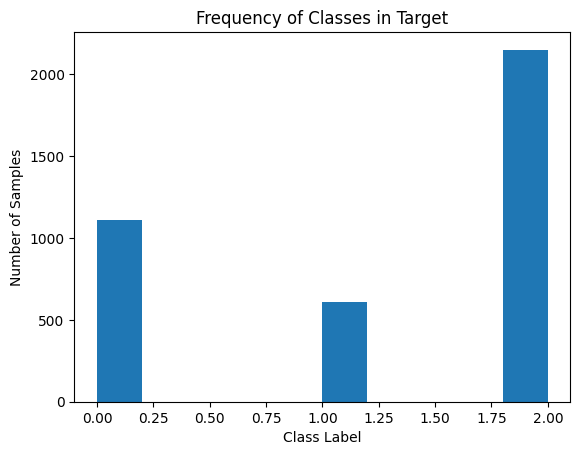

In [128]:
# frequency of classes in target
fig, ax = plt.subplots()
ax.hist(df['Target'])
ax.set_title('Frequency of Classes in Target')
ax.set_xlabel('Class Label')
ax.set_ylabel('Number of Samples')
plt.show()



In [129]:
df.shape

(3869, 25)

In [130]:
df.head(15)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Unemployment rate,Inflation rate,GDP,Target
0,-0.298838,-0.087442,-0.535958,-0.237926,0.330502,-0.324833,2.256513,-0.028428,-1.057618,-1.376689,...,-0.320302,-2.953152,1.475303,-0.546986,-0.492226,0.0,0.960340,-1.170598,0.374305,2
1,-0.298838,-0.897492,2.548640,-0.699989,0.330502,-0.324833,-0.850112,-0.028428,1.226282,0.867288,...,-0.320302,-2.953152,1.475303,-0.546986,-0.492226,0.0,-0.145257,0.109240,0.820326,0
2,-0.298838,0.028280,0.235192,1.065394,0.330502,-0.324833,-0.850112,-0.028428,1.289724,0.867288,...,-0.320302,0.338621,-0.677827,-0.546986,-0.343791,0.0,-0.644559,-1.547021,-1.461422,2
3,3.258719,1.301216,-0.535958,-3.351832,-3.025699,-0.324833,-2.648684,-0.028428,1.226282,0.867288,...,-0.320302,0.338621,-0.677827,-0.546986,-0.640661,0.0,0.960340,-1.170598,0.374305,2
4,3.258719,1.301216,-0.535958,1.612839,-3.025699,1.543211,0.057350,-0.028428,1.226282,0.867288,...,3.122054,0.338621,1.475303,-0.546986,4.109262,0.0,1.780622,-0.718891,-0.428532,2
5,-0.298838,-0.897492,-0.535958,0.379833,0.330502,-0.324833,0.784954,-0.028428,0.084332,0.933287,...,-0.320302,0.338621,-0.677827,-0.546986,-0.640661,0.0,1.530971,1.163224,-1.902747,2
6,-0.298838,-0.897492,1.777490,-0.237926,0.330502,-0.324833,-1.095371,-0.028428,1.226282,0.867288,...,-0.320302,-2.953152,1.475303,-0.546986,-0.046921,0.0,1.530971,1.163224,-1.902747,0
7,-0.298838,-0.897492,-0.535958,-0.278105,0.330502,-0.324833,0.457941,-0.028428,-1.057618,-0.320700,...,3.122054,-2.953152,-0.677827,-0.546986,-0.640661,0.0,-0.822882,0.109240,1.651332,0
8,-0.298838,-0.897492,-0.535958,0.806739,0.330502,-0.324833,0.539694,-0.028428,1.289724,-0.320700,...,-0.320302,0.338621,-0.677827,-0.546986,-0.640661,0.0,0.960340,0.109240,0.374305,2
9,-0.298838,-0.897492,-0.535958,0.379833,0.330502,-0.324833,0.294434,-0.028428,0.084332,0.933287,...,-0.320302,0.338621,-0.677827,1.828199,-0.640661,0.0,0.532367,1.840785,-0.794738,2


**DATA SPLIT**

In [131]:
#Data Split

In [132]:
X = df.drop('Target', axis=1)
y = df['Target']

In [133]:
#Train 80% Test 20 % Statified
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [134]:
#Split for validation 80% of 80% and 20% of 80% . Stratified
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

In [135]:
#saving after test and train
train = pd.concat([X_train, y_train], axis=1)
val = pd.concat([X_val, y_val], axis=1)
test = pd.concat([X_test, y_test], axis=1)
train.to_csv('academic_success_train.csv', index=False)
val.to_csv('academic_success_val.csv', index=False)
test.to_csv('academic_success_test.csv', index=False)

In [136]:
#show class distribution in each split
print(y_train.value_counts(normalize=True))
print(y_val.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Target
2    0.555735
0    0.286753
1    0.157512
Name: proportion, dtype: float64
Target
2    0.555735
0    0.287561
1    0.156704
Name: proportion, dtype: float64
Target
2    0.555556
0    0.286822
1    0.157623
Name: proportion, dtype: float64


**Model Training**

In [137]:
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

# Load the train, validation, and test sets
train = pd.read_csv('academic_success_train.csv')
val = pd.read_csv('academic_success_val.csv')
test = pd.read_csv('academic_success_test.csv')

X_train = train.drop('Target', axis=1)
y_train = train['Target']
X_val = val.drop('Target', axis=1)
y_val = val['Target']
X_test = test.drop('Target', axis=1)
y_test = test['Target']

# Standardize features for neural networks
scaler = StandardScaler()
X_train_nn = scaler.fit_transform(X_train)
X_val_nn = scaler.transform(X_val)
X_test_nn = scaler.transform(X_test)

# Logistic Regression
print("\n--- Logistic Regression ---")
lr = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=200, random_state=42)
lr.fit(X_train, y_train)
y_val_pred = lr.predict(X_val)
y_test_pred = lr.predict(X_test)
print(f"Validation Accuracy: {accuracy_score(y_val, y_val_pred):.4f}")
print("Validation Classification Report:")
print(classification_report(y_val, y_val_pred))
print(f"Test Accuracy: {accuracy_score(y_test, y_test_pred):.4f}")
print("Test Classification Report:")
print(classification_report(y_test, y_test_pred))
print("Test Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

# Naive Bayes
print("\n--- Naive Bayes ---")
nb = GaussianNB()
nb.fit(X_train, y_train)
y_val_pred = nb.predict(X_val)
y_test_pred = nb.predict(X_test)
print(f"Validation Accuracy: {accuracy_score(y_val, y_val_pred):.4f}")
print("Validation Classification Report:")
print(classification_report(y_val, y_val_pred))
print(f"Test Accuracy: {accuracy_score(y_test, y_test_pred):.4f}")
print("Test Classification Report:")
print(classification_report(y_test, y_test_pred))
print("Test Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))


# Neural Network (MLPClassifier)
print("\n--- Neural Network (MLPClassifier) ---")
mlp = MLPClassifier(hidden_layer_sizes=(128, 64), activation='relu', solver='adam',
                    max_iter=100, random_state=42, early_stopping=True, validation_fraction=0.1)
mlp.fit(X_train_nn, y_train)
y_val_pred = mlp.predict(X_val_nn)
y_test_pred = mlp.predict(X_test_nn)
print(f"Validation Accuracy: {accuracy_score(y_val, y_val_pred):.4f}")
print("Validation Classification Report:")
print(classification_report(y_val, y_val_pred))
print(f"Test Accuracy: {accuracy_score(y_test, y_test_pred):.4f}")
print("Test Classification Report:")
print(classification_report(y_test, y_test_pred))
print("Test Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))


--- Logistic Regression ---
Validation Accuracy: 0.6494
Validation Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.48      0.56       178
           1       0.00      0.00      0.00        97
           2       0.64      0.92      0.76       344

    accuracy                           0.65       619
   macro avg       0.44      0.47      0.44       619
weighted avg       0.55      0.65      0.58       619

Test Accuracy: 0.6357
Test Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.41      0.51       222
           1       0.33      0.01      0.02       122
           2       0.63      0.93      0.75       430

    accuracy                           0.64       774
   macro avg       0.54      0.45      0.43       774
weighted avg       0.59      0.64      0.57       774

Test Confusion Matrix:
[[ 92   1 129]
 [ 20   1 101]
 [ 30   1 399]]

--- Naive Bayes ---
Validat

C:\Users\Roy\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\Roy\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Roy\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Roy\

Validation Accuracy: 0.6559
Validation Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.52      0.58       178
           1       0.50      0.05      0.09        97
           2       0.66      0.90      0.76       344

    accuracy                           0.66       619
   macro avg       0.60      0.49      0.48       619
weighted avg       0.63      0.66      0.60       619

Test Accuracy: 0.6279
Test Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.47      0.52       222
           1       0.20      0.02      0.03       122
           2       0.65      0.88      0.75       430

    accuracy                           0.63       774
   macro avg       0.48      0.46      0.43       774
weighted avg       0.56      0.63      0.57       774

Test Confusion Matrix:
[[104   5 113]
 [ 29   2  91]
 [ 47   3 380]]


In [138]:
#UNSUPERVISED

In [139]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [140]:
#k-mean applied to relevant features
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
target_candidates = ['target', 'Target', 'label', 'Label', 'class', 'Class']
target_col = None
for col in target_candidates:
    if col in numeric_cols:
        target_col = col
        numeric_cols.remove(col)
        break

In [141]:
X = df[numeric_cols].copy()

In [142]:
#elbow method to find optimal no of clusters

In [143]:
k_range = range(1, 11)  # Try K from 1 to 10
SSE = []
for k in k_range:
    # Fit KMeans and record the inertia (SSE)
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    SSE.append(km.inertia_)

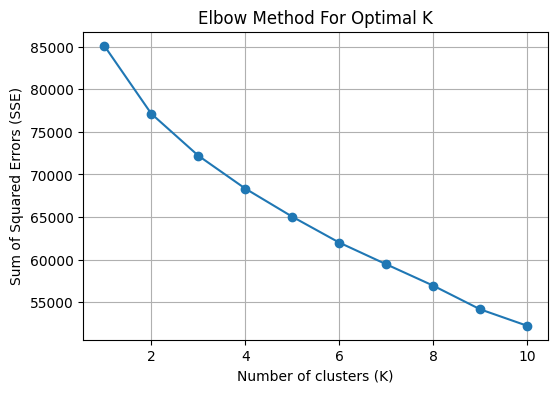

In [144]:
#plotting the SSE for each K to visually find the "elbow"
plt.figure(figsize=(6,4))
plt.plot(k_range, SSE, marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Sum of Squared Errors (SSE)')
plt.title('Elbow Method For Optimal K')
plt.grid(True)
plt.show()

In [145]:
optimal_k = 3

In [146]:
#fit KMeans on all selected numeric features and adding cluster labels to the DataFrame
km = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
y_predicted = km.fit_predict(X)
df['Group_cluster'] = y_predicted

In [147]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3869 entries, 0 to 3868
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Marital status                  3869 non-null   float64
 1   Application mode                3869 non-null   float64
 2   Application order               3869 non-null   float64
 3   Course                          3869 non-null   float64
 4   Daytime/evening attendance	     3869 non-null   float64
 5   Previous qualification          3869 non-null   float64
 6   Previous qualification (grade)  3869 non-null   float64
 7   Nacionality                     3869 non-null   float64
 8   Mother's qualification          3869 non-null   float64
 9   Father's qualification          3869 non-null   float64
 10  Mother's occupation             3869 non-null   float64
 11  Father's occupation             3869 non-null   float64
 12  Admission grade                 38

C:\Users\Roy\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


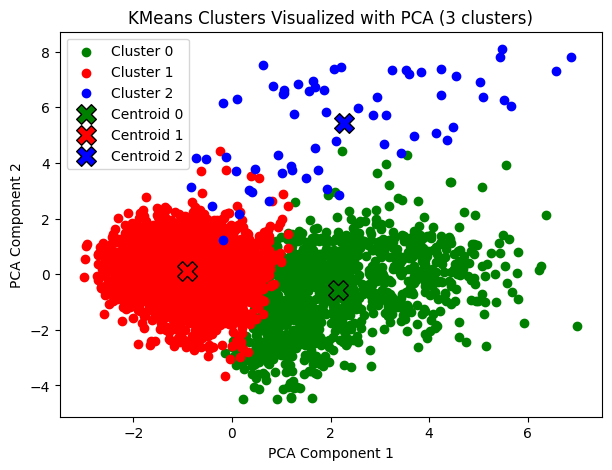

In [148]:
#plotting
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(7,5))
color = ['green', 'red', 'blue', 'purple', 'black', 'yellow']
for i in range(optimal_k):
    plt.scatter(X_pca[df['Group_cluster']==i, 0],
                X_pca[df['Group_cluster']==i, 1],
                color=color[i], label=f'Cluster {i}')
# Plot centroids in PCA space
centroids_pca = pca.transform(km.cluster_centers_)
for i in range(optimal_k):
    plt.scatter(centroids_pca[i,0], centroids_pca[i,1],
                color=color[i], s=200, marker='X', edgecolor='k', label=f'Centroid {i}')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title(f'KMeans Clusters Visualized with PCA ({optimal_k} clusters)')
plt.legend()
plt.show()

In [149]:
print(df['Group_cluster'].value_counts())

Group_cluster
1    2725
0    1080
2      64
Name: count, dtype: int64


**Model Evaluation**

In [150]:
#standardize features for all models
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [151]:
#ROC Curve and Confusion Matrix Visualization
models = {
  "Logistic Regression": lr,
  "Naive Bayes": nb,
  "Neural Network (MLPClassifier)": mlp
}

C:\Users\Roy\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
C:\Users\Roy\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


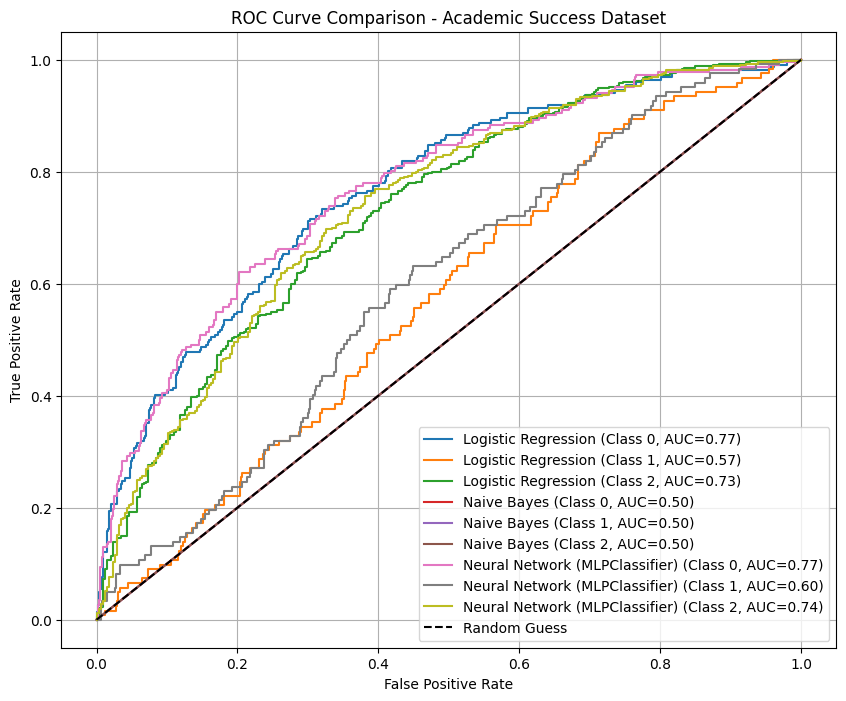

C:\Users\Roy\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


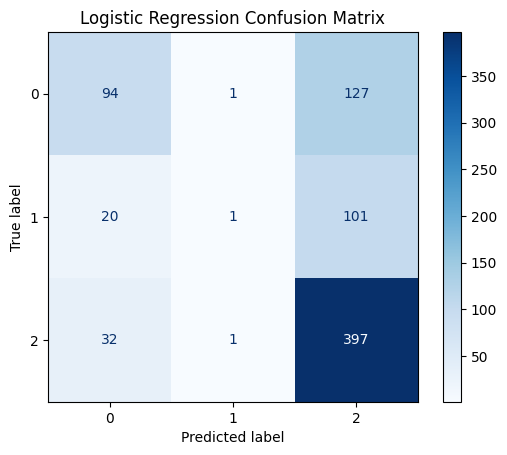

Logistic Regression Accuracy: 0.6356589147286822


C:\Users\Roy\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


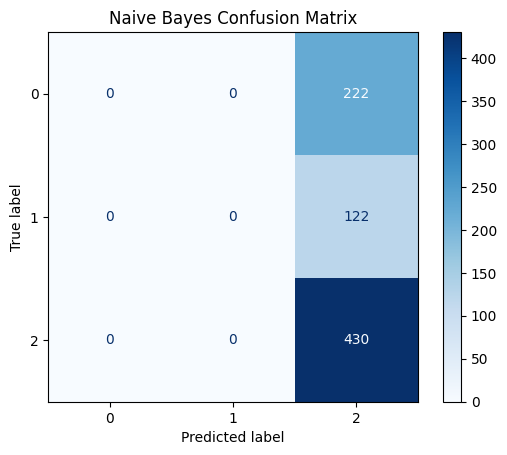

Naive Bayes Accuracy: 0.5555555555555556


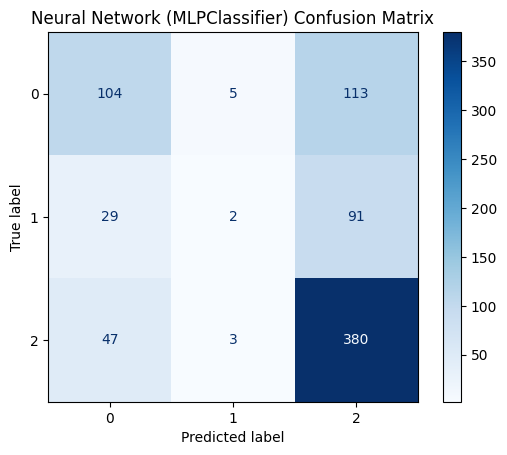

Neural Network (MLPClassifier) Accuracy: 0.627906976744186


In [152]:
from sklearn.metrics import roc_curve, auc, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 8))
for name, model in models.items():
  if hasattr(model, 'predict_proba'):
    y_probs = model.predict_proba(X_test_scaled)
    if y_probs.shape[1] == 2:
      y_probs = y_probs[:, 1]
    else:
      for i in range(y_probs.shape[1]):
        fpr, tpr, _ = roc_curve((y_test == i).astype(int), y_probs[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{name} (Class {i}, AUC={roc_auc:.2f})")
      continue
  else:
    y_probs = model.decision_function(X_test_scaled)
    if len(np.unique(y_test)) == 2:
      fpr, tpr, _ = roc_curve(y_test, y_probs)
      roc_auc = auc(fpr, tpr)
      plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.2f})")
      continue
    else:
      for i in range(y_probs.shape[1]):
        fpr, tpr, _ = roc_curve((y_test == i).astype(int), y_probs[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{name} (Class {i}, AUC={roc_auc:.2f})")
      continue
  #binary case
  fpr, tpr, _ = roc_curve(y_test, y_probs)
  roc_auc = auc(fpr, tpr)
  plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.2f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - Academic Success Dataset")
plt.legend(loc="lower right")
plt.grid()
plt.show()

for name, model in models.items():
  y_pred = model.predict(X_test_scaled)
  cm = confusion_matrix(y_test, y_pred)
  ConfusionMatrixDisplay(cm).plot(cmap="Blues")
  plt.title(f"{name} Confusion Matrix")
  plt.show()
  print(f"{name} Accuracy:", accuracy_score(y_test, y_pred))

In [ ]:
#Accuracy Table and Classification Reports

results = []
results.append({
  'Model': 'Logistic Regression',
  'Validation Accuracy': accuracy_score(y_val, lr.predict(X_val_scaled)),
  'Test Accuracy': accuracy_score(y_test, lr.predict(X_test_scaled))
})
results.append({
  'Model': 'Naive Bayes',
  'Validation Accuracy': accuracy_score(y_val, nb.predict(X_val_scaled)),
  'Test Accuracy': accuracy_score(y_test, nb.predict(X_test_scaled))
})
results.append({
  'Model': 'Neural Network (MLPClassifier)',
  'Validation Accuracy': accuracy_score(y_val, mlp.predict(X_val_scaled)),
  'Test Accuracy': accuracy_score(y_test, mlp.predict(X_test_scaled))
})

results_df = pd.DataFrame(results)
print("\nAccuracy Comparison Table:")
print(results_df.to_string(index=False))

print("\nClassification Reports (Test Set):")
for name, model, X, y_true in [
  ("Logistic Regression", lr, X_test_scaled, y_test),
  ("Naive Bayes", nb, X_test_scaled, y_test),
  ("Neural Network (MLPClassifier)", mlp, X_test_scaled, y_test)
]:
  y_pred = model.predict(X)
  print(f"\n{name}:")
  print(classification_report(y_true, y_pred))
  print("Confusion Matrix:\n", confusion_matrix(y_true, y_pred))


Accuracy Comparison Table:
                         Model  Validation Accuracy  Test Accuracy
           Logistic Regression             0.644588       0.635659
                   Naive Bayes             0.555735       0.555556
Neural Network (MLPClassifier)             0.655897       0.627907

Classification Reports (Test Set):

Logistic Regression:
              precision    recall  f1-score   support

           0       0.64      0.42      0.51       222
           1       0.33      0.01      0.02       122
           2       0.64      0.92      0.75       430

    accuracy                           0.64       774
   macro avg       0.54      0.45      0.43       774
weighted avg       0.59      0.64      0.57       774

Confusion Matrix:
 [[ 94   1 127]
 [ 20   1 101]
 [ 32   1 397]]

Naive Bayes:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       222
           1       0.00      0.00      0.00       122
           2       0.56

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklear

In [ ]:
# KMeans Clustering
df_full = pd.read_csv('academic_success_dataset_preprocessed.csv')
numeric_cols = [col for col in df_full.select_dtypes(include=[np.number]).columns if col != 'Target']
X_cluster = df_full[numeric_cols].values
optimal_k = 3  # Set based on elbow method or domain knowledge
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_cluster)
print("\nKMeans Cluster Centers:")
print(kmeans.cluster_centers_)
print("Prediction for the KMeans Cluster")
print(kmeans_labels)



KMeans Cluster Centers:
[[ 6.95039650e-01  1.06511602e+00 -4.91729084e-01 -2.89427978e-01
  -7.65463713e-01  7.46762553e-01 -7.23599551e-03 -2.00882968e-02
   2.86512071e-01  1.99235748e-01  3.26392941e-03 -1.36927074e-01
   1.20544180e-01 -5.87681227e-01  0.00000000e+00  3.22950544e-01
  -3.40440152e-01  3.22053968e-01 -3.31659657e-01  1.02727708e+00
   0.00000000e+00  1.54442815e-01 -6.10387604e-02 -8.04451916e-02]
 [-2.80554410e-01 -4.24622602e-01  1.95558375e-01  1.28841231e-01
   3.10788750e-01 -2.94087381e-01  5.17061091e-03  8.63981512e-03
  -1.23507051e-01 -8.66735092e-02 -1.06884936e-01 -1.21314332e-01
  -4.12638603e-02  2.43199216e-01  0.00000000e+00 -1.29481170e-01
   1.42855027e-01 -1.27687965e-01  1.39236455e-01 -4.19479704e-01
   0.00000000e+00 -4.04634804e-02  9.71682503e-03  3.00723187e-02]
 [ 2.01442995e-01  8.25242391e-02 -1.78417996e-02 -5.95185469e-01
  -2.98785627e-01 -9.61920797e-02 -9.78536405e-02 -2.84282424e-02
   4.17400908e-01  3.23824936e-01  4.49416027e+00

/tmp/ipython-input-801770308.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=model_names, y=accuracies, palette="mako")


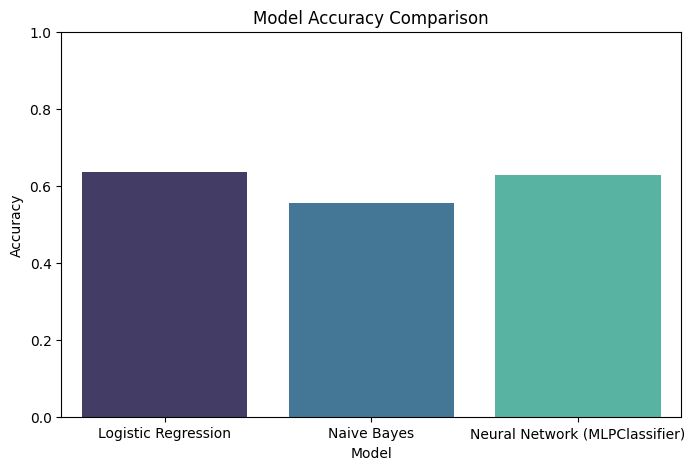

In [ ]:
# Bar chart for model comparison
import matplotlib.pyplot as plt
import seaborn as sns

model_names = results_df['Model'].tolist()
accuracies = results_df['Test Accuracy'].tolist()

plt.figure(figsize=(8,5))
sns.barplot(x=model_names, y=accuracies, palette="mako")
plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

In [ ]:
#Accuracy = Logistic Regression
#F1 Average = Neural Network
#Stability = Neural Network
#Strogest Per class = Neural Network
 #Class  Logistic F1    MLP F1 Better Model
#0      0     0.510870  0.517413          MLP
#1      1     0.016000  0.030303          MLP
#2      2     0.752607  0.749507     Logistic